In [2]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

df = pd.read_csv("PhiUSIIL_Phishing_URL_Dataset.csv")
print(df.shape)
print(df.columns.tolist())
df.head()

(235795, 56)
['FILENAME', 'URL', 'URLLength', 'Domain', 'DomainLength', 'IsDomainIP', 'TLD', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'Title', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef', 'label']


,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,...,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,...,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,...,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,...,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,...,1,0,1,244,15,34,72,1,85,1


### Newly Added Cell
This is an example of a cell added to your notebook. You can write your custom code or text in cells like this.

In [3]:
print(df.dtypes)
print(df.isna().sum(),"missing values")

FILENAME                       object
URL                            object
URLLength                       int64
Domain                         object
DomainLength                    int64
IsDomainIP                      int64
TLD                            object
URLSimilarityIndex            float64
CharContinuationRate          float64
TLDLegitimateProb             float64
URLCharProb                   float64
TLDLength                       int64
NoOfSubDomain                   int64
HasObfuscation                  int64
NoOfObfuscatedChar              int64
ObfuscationRatio              float64
NoOfLettersInURL                int64
LetterRatioInURL              float64
NoOfDegitsInURL                 int64
DegitRatioInURL               float64
NoOfEqualsInURL                 int64
NoOfQMarkInURL                  int64
NoOfAmpersandInURL              int64
NoOfOtherSpecialCharsInURL      int64
SpacialCharRatioInURL         float64
IsHTTPS                         int64
LineOfCode  

In [5]:
# Analyze the target status column 'label'
class_counts = df['label'].value_counts()
class_percentages = df['label'].value_counts(normalize=True) * 100

# Combine counts and percentages for a clean summary
summary_df = pd.DataFrame({
    'Count': class_counts,
    'Percentage (%)': class_percentages
})

print("Target Column 'label' Distribution:")
display(summary_df)

Target Column 'label' Distribution:


,Count,Percentage (%)
label,,
1,134850,57.189508
0,100945,42.810492


In [6]:
df["is_phishing"] = (df["label"] == 0).astype(int)
print(df["is_phishing"].value_counts())


is_phishing
0    134850
1    100945
Name: count, dtype: int64


In [7]:
df = df.drop_duplicates().dropna()

X = df.select_dtypes(include="number").drop(columns=["label", "is_phishing"])
y = df["is_phishing"]
print(X.shape)
print(X.columns.tolist())


(235795, 50)
['URLLength', 'DomainLength', 'IsDomainIP', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef']


In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())


(188636, 50) (47159, 50)
0.42810492164804176 0.42810492164804176


In [9]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             average_precision_score)

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
}

for name, m in models.items():
    m.fit(X_train, y_train)
    preds = m.predict(X_test)
    probs = m.predict_proba(X_test)[:, 1]
    print("\n==", name, "==")
    print(classification_report(y_test, preds, target_names=["legitimate", "phishing"]))
    print("PR-AUC:", round(average_precision_score(y_test, probs), 4))
    print(confusion_matrix(y_test, preds))



== Logistic Regression ==
              precision    recall  f1-score   support

  legitimate       1.00      1.00      1.00     26970
    phishing       1.00      1.00      1.00     20189

    accuracy                           1.00     47159
   macro avg       1.00      1.00      1.00     47159
weighted avg       1.00      1.00      1.00     47159

PR-AUC: 1.0
[[26970     0]
 [    5 20184]]

== Random Forest ==
              precision    recall  f1-score   support

  legitimate       1.00      1.00      1.00     26970
    phishing       1.00      1.00      1.00     20189

    accuracy                           1.00     47159
   macro avg       1.00      1.00      1.00     47159
weighted avg       1.00      1.00      1.00     47159

PR-AUC: 1.0
[[26970     0]
 [    0 20189]]


URLSimilarityIndex    0.178005
NoOfExternalRef       0.165495
LineOfCode            0.154835
NoOfSelfRef           0.105136
NoOfImage             0.083222
NoOfJS                0.070344
NoOfCSS               0.032452
HasSocialNet          0.032032
HasCopyrightInfo      0.026687
IsHTTPS               0.023774
dtype: float64


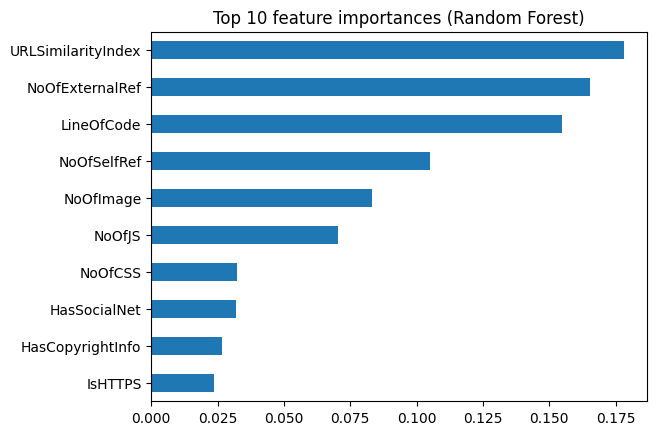

In [10]:
import os
os.makedirs("images", exist_ok=True)

rf = models["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print(imp.head(10))

imp.head(10).sort_values().plot(kind="barh")
plt.title("Top 10 feature importances (Random Forest)")
plt.savefig("images/feature_importance.png", bbox_inches="tight")
plt.show()


In [11]:
drop_cols = ["URLSimilarityIndex"]   # add other top features from the list above if one clearly dominates
Xtr, Xte = X_train.drop(columns=drop_cols), X_test.drop(columns=drop_cols)

rf2 = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf2.fit(Xtr, y_train)
p2 = rf2.predict(Xte)
print(classification_report(y_test, p2, target_names=["legitimate", "phishing"], digits=4))
print(confusion_matrix(y_test, p2))


              precision    recall  f1-score   support

  legitimate     0.9998    0.9999    0.9998     26970
    phishing     0.9998    0.9997    0.9998     20189

    accuracy                         0.9998     47159
   macro avg     0.9998    0.9998    0.9998     47159
weighted avg     0.9998    0.9998    0.9998     47159

[[26966     4]
 [    6 20183]]


In [ ]:
from google.colab import drive
drive.mount('/content/drive')